## CSC311 Project Data Exploration

#### 1. Dataset Split

In [112]:
import numpy as np
import pandas as pd
import os

def split_by_student(ids, val_frac=0.15, test_frac=0.15, seed=42):
    """
    Splits the unique student ids into train/val/test groups. All three rows
    from the same student end up in the same split, so the model is never
    tested on a student it has already seen during training.
    """
    rng = np.random.default_rng(seed)
    students = rng.permutation(ids.unique())
    n_test = int(len(students) * test_frac)
    n_val = int(len(students) * val_frac)
    test_ids = students[:n_test]
    val_ids = students[n_test:n_test + n_val]
    train_ids = students[n_test + n_val:]
    return ids.isin(train_ids), ids.isin(val_ids), ids.isin(test_ids)

df = pd.read_csv('csc311_project_training_202609.csv')

# Rename the columns
column_mapping = {
    'How easy do you think it would be for someone with no prior experience to start playing this sport recreationally? Rate it on a scale from 0 to 10, where 0 means extremely difficult and 10 means extremely easy.': 'ease_of_play',
    'Success in this sport depends heavily on strategy and planning.': 'strategy_dependent',
    'Players must be comfortable with a high risk of injury.': 'injury_risk',
    'Individual brilliance can outweigh teamwork in this sport.': 'individual_brilliance',
    'Where might you play this sport?': 'locations',
    'During which seasons would you be most likely to play this sport recreationally in Toronto?': 'seasons',
    'What types of music do you most associate with this sport?': 'music_genre',
    'What foods and drinks do you associate with watching this sport in the place or culture you know best?': 'food_drink',
    'What colour do you associate with this sport?': 'color',
    'Which song do you associate with this sport?': 'song',
    'How do you feel when you watch this sport?': 'emotions',
    'How much would you be willing to pay for a decent seat at a professional competition of this sport?': 'ticket_price'
}
df = df.rename(columns=column_mapping)
print("Column renamed to: " + str(list(df.columns)))

# Split the data set based on ID (training 70%, validation 15%, test 15%)
train_mask, val_mask, test_mask = split_by_student(df['id'])

train_df = df[train_mask].copy()
val_df = df[val_mask].copy()
test_df = df[test_mask].copy()

print(f"Total rows: {len(df)}")
print(f"Train rows: {len(train_df)}")
print(f"Validation rows: {len(val_df)}")
print(f"Test rows: {len(test_df)}")

os.makedirs('raw', exist_ok=True)
train_df.to_csv('raw/train.csv', index=False)
val_df.to_csv('raw/val.csv', index=False)
test_df.to_csv('raw/test.csv', index=False)

print("Datasets successfully saved to raw/")

Column renamed to: ['id', 'ease_of_play', 'strategy_dependent', 'injury_risk', 'individual_brilliance', 'locations', 'seasons', 'music_genre', 'food_drink', 'color', 'song', 'emotions', 'ticket_price', 'label']
Total rows: 870
Train rows: 612
Validation rows: 129
Test rows: 129
Datasets successfully saved to raw/


#### 2. Feature Distributions

Overall Dataset (All Sports)

--- Summary Table: ease_of_play ---
              Count  Percentage (%)
ease_of_play                       
0.0               7            1.15
1.0              14            2.31
2.0              43            7.08
3.0              86           14.17
4.0              73           12.03
5.0              81           13.34
6.0              75           12.36
7.0              78           12.85
8.0              83           13.67
9.0              45            7.41
10.0             21            3.46 



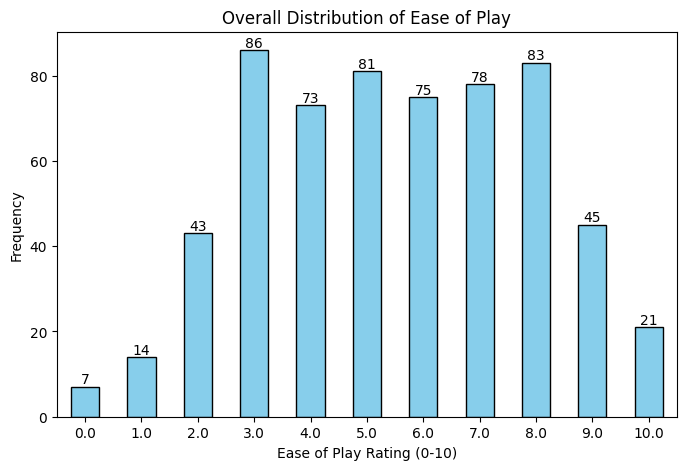

--- Summary Table: strategy_dependent ---
                    Count  Percentage (%)
strategy_dependent                       
Strongly agree        134           22.11
Agree                 285           47.03
Neutral               121           19.97
Disagree               60            9.90
Strongly disagree       6            0.99 



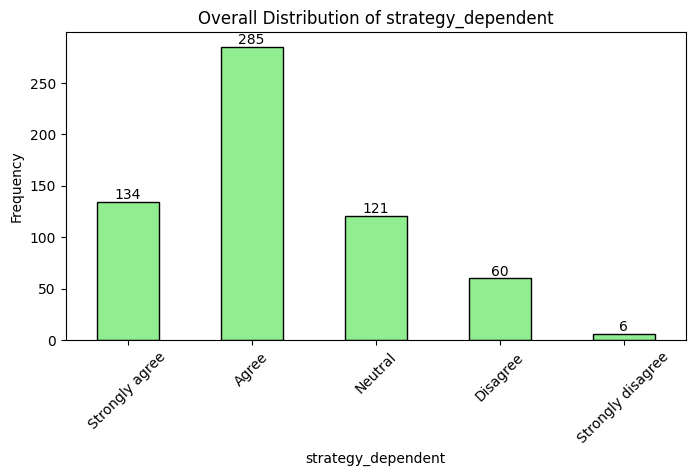

--- Summary Table: injury_risk ---
                   Count  Percentage (%)
injury_risk                             
Strongly agree       100           16.47
Agree                229           37.73
Neutral              152           25.04
Disagree             109           17.96
Strongly disagree     17            2.80 



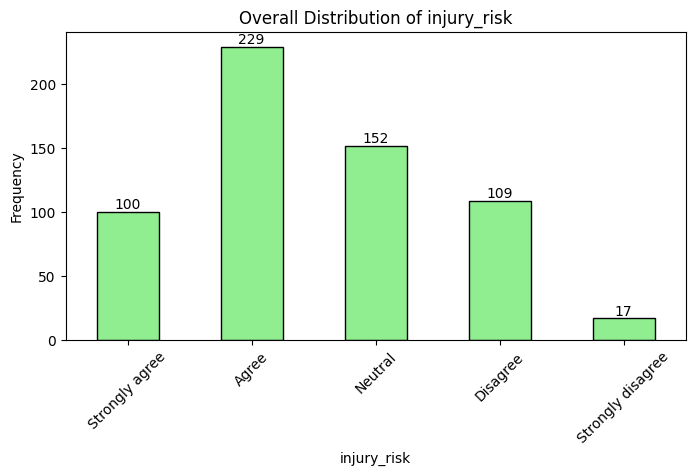

--- Summary Table: individual_brilliance ---
                       Count  Percentage (%)
individual_brilliance                       
Strongly agree           100           16.50
Agree                    215           35.48
Neutral                  139           22.94
Disagree                 125           20.63
Strongly disagree         27            4.46 



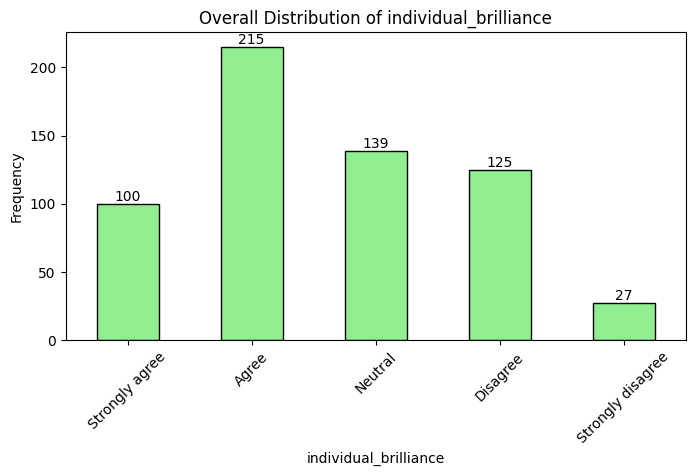

--- Summary Table: locations (Multi-select) ---
                               Count  Percentage (%)
locations                                           
Outdoor public space             548           21.06
School or university facility    521           20.02
Community recreation facility    433           16.64
Private sports facility          414           15.91
Indoor facility                  366           14.07
At home or nearby                256            9.84
Others                            64            2.46 



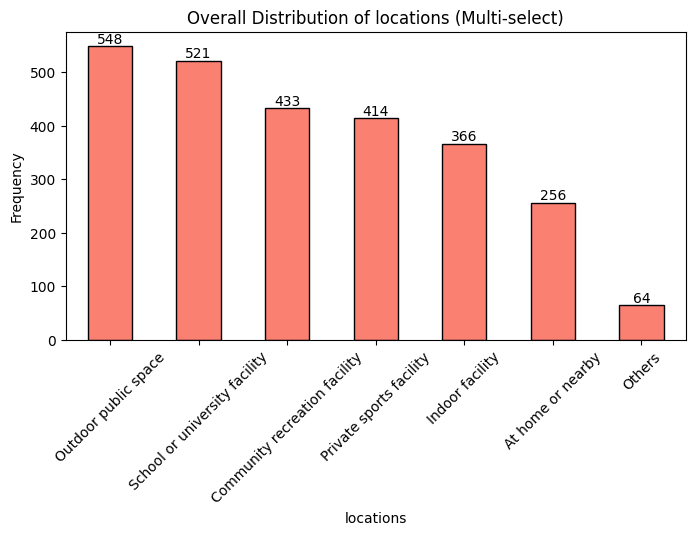

--- Summary Table: seasons (Multi-select) ---
         Count  Percentage (%)
seasons                       
Summer     562           34.69
Spring     464           28.64
Fall       453           27.96
Winter     141            8.70 



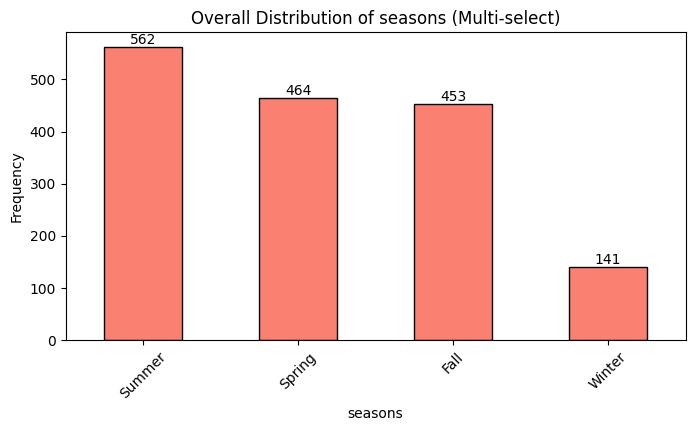

--- Summary Table: music_genre (Multi-select) ---
                     Count  Percentage (%)
music_genre                               
Hip-hop or rap         306           25.31
Pop                    256           21.17
Rock                   150           12.41
Electronic or dance    140           11.58
No particular type     115            9.51
Latin                   95            7.86
Country                 79            6.53
Folk or traditional     32            2.65
Classical or jazz       19            1.57
Other                   17            1.41 



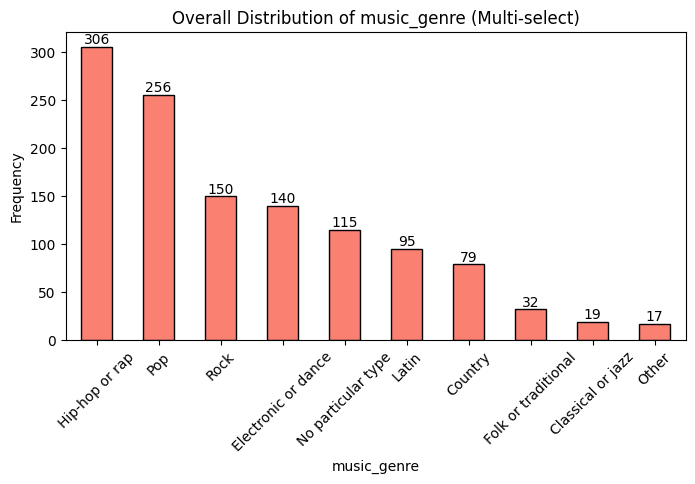


--- Summary Table: ticket_price ---
                   Count  Percentage (%)
Bin Range                               
0.00 - 250.00        427           76.25
250.00 - 500.00       60           10.71
500.00 - 750.00       40            7.14
750.00 - 1000.00       4            0.71
1000.00 - 1250.00     22            3.93
1250.00 - 1500.00      0            0.00
1500.00 - 1750.00      1            0.18
1750.00 - 2000.00      0            0.00
2000.00 - 2250.00      4            0.71
2250.00 - 2500.00      0            0.00
2500.00 - 2750.00      0            0.00
2750.00 - 3000.00      0            0.00
3000.00 - 3250.00      0            0.00
3250.00 - 3500.00      0            0.00
3500.00 - 3750.00      0            0.00
3750.00 - 4000.00      0            0.00
4000.00 - 4250.00      0            0.00
4250.00 - 4500.00      0            0.00
4500.00 - 4750.00      0            0.00
4750.00 - 5000.00      2            0.36 



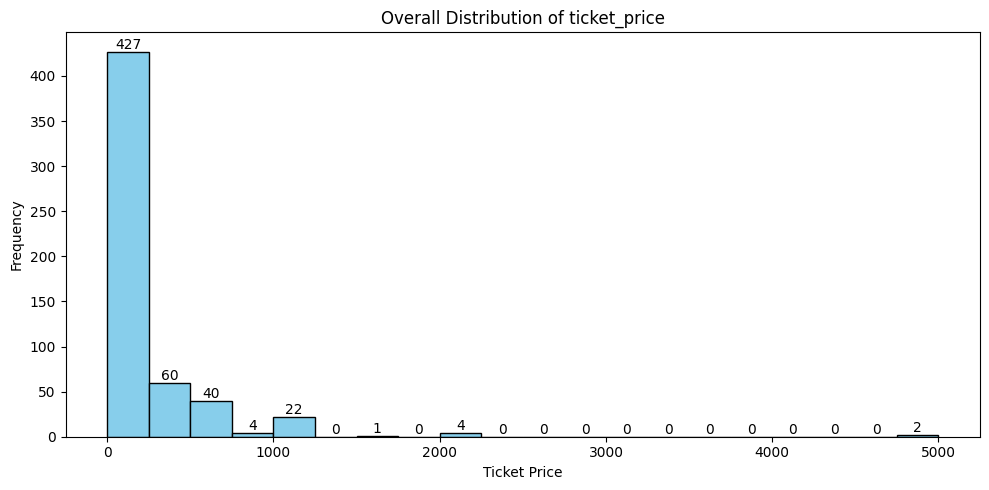

In [113]:
import pandas as pd
import matplotlib.pyplot as plt

train_df = pd.read_csv('raw/train.csv')

# Define standard orderings
likert_order = ['Strongly agree', 'Agree', 'Neutral', 'Disagree', 'Strongly disagree']
ease_order = list(range(11)) 

# Helper function to sort ordinal data without creating empty categories for missing data
def apply_ordinal_sort(data, order_list):
    valid_order = [item for item in order_list if item in data.index]
    return data.loc[valid_order]

# 1. Overall: Ease of Play
ease_data = train_df['ease_of_play'].dropna()
ease_counts = apply_ordinal_sort(ease_data.value_counts(), ease_order)
ease_pct = apply_ordinal_sort(ease_data.value_counts(normalize=True), ease_order) * 100

print("--- Summary Table: ease_of_play ---")
print(pd.DataFrame({'Count': ease_counts, 'Percentage (%)': ease_pct}).round(2), "\n")

plt.figure(figsize=(8, 5))
ax1 = ease_counts.plot(kind='bar', color='skyblue', edgecolor='black')
ax1.bar_label(ax1.containers[0])
plt.title('Overall Distribution of Ease of Play')
plt.xlabel('Ease of Play Rating (0-10)')
plt.ylabel('Frequency')
plt.xticks(rotation=0)
plt.show()

# 2. Overall: Likert Scales
likert_cols = ['strategy_dependent', 'injury_risk', 'individual_brilliance']
for col in likert_cols:
    col_data = train_df[col].dropna()
    counts = apply_ordinal_sort(col_data.value_counts(), likert_order)
    percentages = apply_ordinal_sort(col_data.value_counts(normalize=True), likert_order) * 100
    
    print(f"--- Summary Table: {col} ---")
    print(pd.DataFrame({'Count': counts, 'Percentage (%)': percentages}).round(2), "\n")

    plt.figure(figsize=(8, 4))
    ax2 = counts.plot(kind='bar', color='lightgreen', edgecolor='black')
    ax2.bar_label(ax2.containers[0])
    plt.title(f'Overall Distribution of {col}')
    plt.ylabel('Frequency')
    plt.xticks(rotation=45) 
    plt.show()

# 3. Overall: Multi-Select Data
multiselect_cols = ['locations', 'seasons', 'music_genre']
for col in multiselect_cols:
    exploded_data = train_df[col].dropna().str.split(',').explode().str.strip()
    
    counts = exploded_data.value_counts()
    percentages = exploded_data.value_counts(normalize=True) * 100
    
    print(f"--- Summary Table: {col} (Multi-select) ---")
    print(pd.DataFrame({'Count': counts, 'Percentage (%)': percentages}).round(2), "\n")
    
    plt.figure(figsize=(8, 4))
    ax3 = counts.plot(kind='bar', color='salmon', edgecolor='black')
    ax3.bar_label(ax3.containers[0])
    plt.title(f'Overall Distribution of {col} (Multi-select)')
    plt.ylabel('Frequency')
    plt.xticks(rotation=45)
    plt.show()

# 4. Overall: Ticket Price
print(f"\n--- Summary Table: ticket_price ---")

# Extract numeric values using regex and drop missing/unmatchable values
prices = train_df['ticket_price'].astype(str).str.extract(r'(\d+\.?\d*)')[0].astype(float).dropna()

plt.figure(figsize=(10, 5))
ax4 = prices.plot(kind='hist', bins=20, color='skyblue', edgecolor='black')
ax4.bar_label(ax4.containers[0])
plt.title('Overall Distribution of ticket_price')
plt.xlabel('Ticket Price')
plt.ylabel('Frequency')

# Build the summary table using the exact bin edges Matplotlib calculated for the plot
counts, bin_edges = np.histogram(prices, bins=20)
bin_labels = [f"{bin_edges[i]:.2f} - {bin_edges[i+1]:.2f}" for i in range(len(bin_edges)-1)]
numeric_pct = (counts / counts.sum()) * 100

summary_table = pd.DataFrame({
    'Bin Range': bin_labels,
    'Count': counts, 
    'Percentage (%)': numeric_pct
}).round(2).set_index('Bin Range')

print(summary_table, "\n")
plt.tight_layout()
plt.show()

Individual Sports

--- Summary Table: ease_of_play (Counts) ---
label         Baseball  Basketball  Soccer
ease_of_play                              
0.0                  5           1       1
1.0                 11           2       1
2.0                 32           4       7
3.0                 51          16      19
4.0                 32          20      21
5.0                 30          32      19
6.0                 14          38      23
7.0                 13          30      35
8.0                  8          32      43
9.0                  4          19      22
10.0                 2           8      11

--- Summary Table: ease_of_play (Percentages) ---
label         Baseball  Basketball  Soccer
ease_of_play                              
0.0               2.48        0.50    0.49
1.0               5.45        0.99    0.49
2.0              15.84        1.98    3.45
3.0              25.25        7.92    9.36
4.0              15.84        9.90   10.34
5.0              14.85       15.84    9.36
6

<Figure size 1400x500 with 0 Axes>

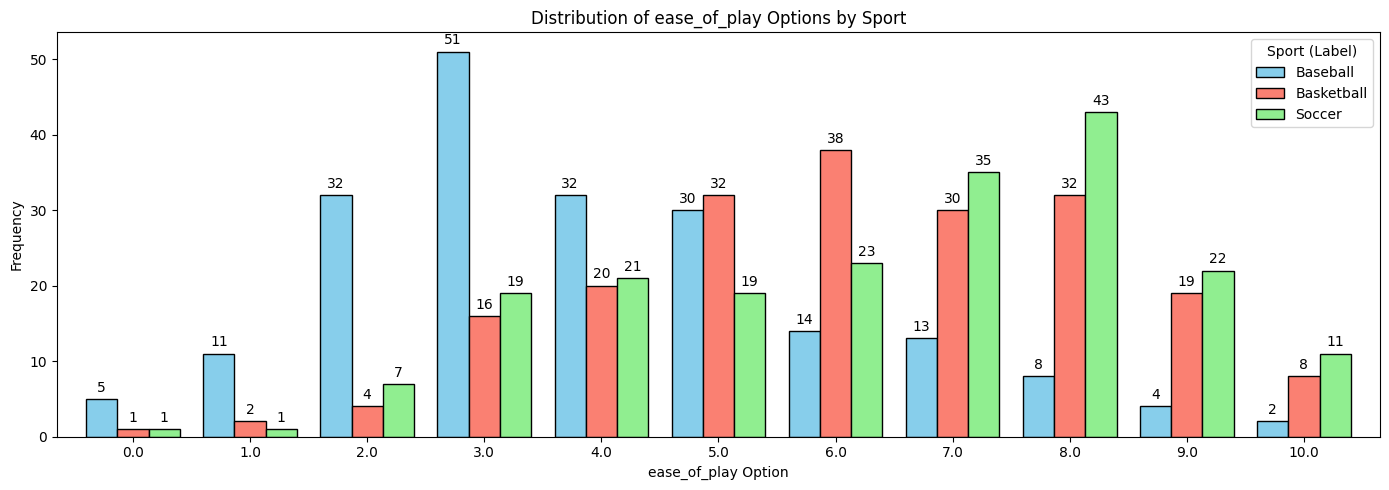

--- Summary Table: strategy_dependent (Counts) ---
label               Baseball  Basketball  Soccer
strategy_dependent                              
Strongly agree            46          41      47
Agree                     63         109     113
Neutral                   57          38      26
Disagree                  33          12      15
Strongly disagree          3           1       2

--- Summary Table: strategy_dependent (Percentages) ---
label               Baseball  Basketball  Soccer
strategy_dependent                              
Strongly agree         22.77       20.40   23.15
Agree                  31.19       54.23   55.67
Neutral                28.22       18.91   12.81
Disagree               16.34        5.97    7.39
Strongly disagree       1.49        0.50    0.99 



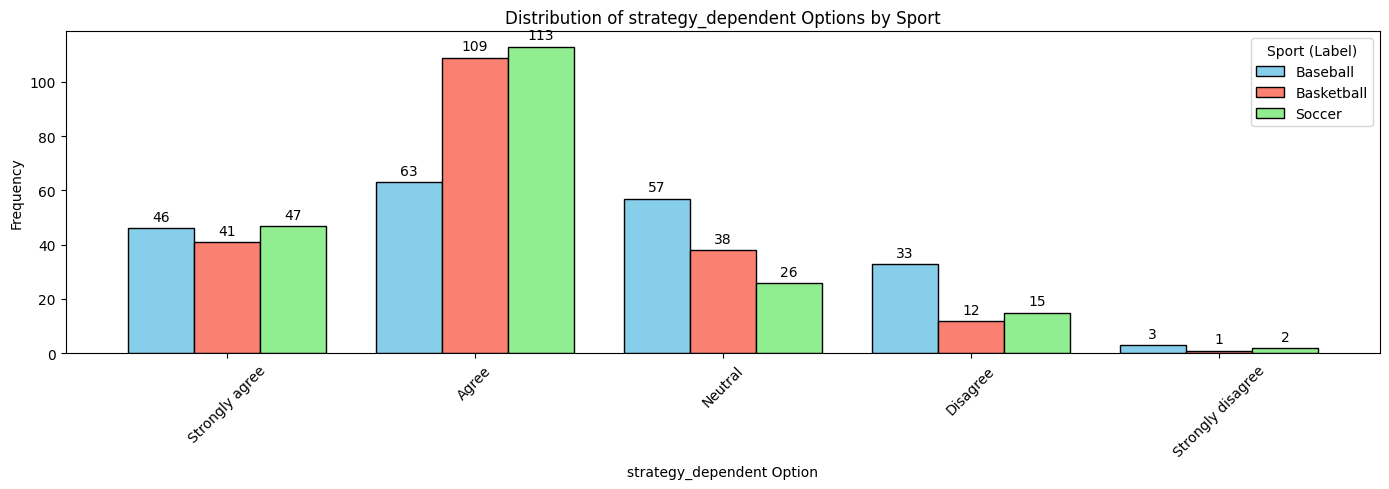

--- Summary Table: injury_risk (Counts) ---
label              Baseball  Basketball  Soccer
injury_risk                                    
Strongly agree            9          48      43
Agree                    43          89      97
Neutral                  70          44      38
Disagree                 68          18      23
Strongly disagree        12           3       2

--- Summary Table: injury_risk (Percentages) ---
label              Baseball  Basketball  Soccer
injury_risk                                    
Strongly agree         4.46       23.76   21.18
Agree                 21.29       44.06   47.78
Neutral               34.65       21.78   18.72
Disagree              33.66        8.91   11.33
Strongly disagree      5.94        1.49    0.99 



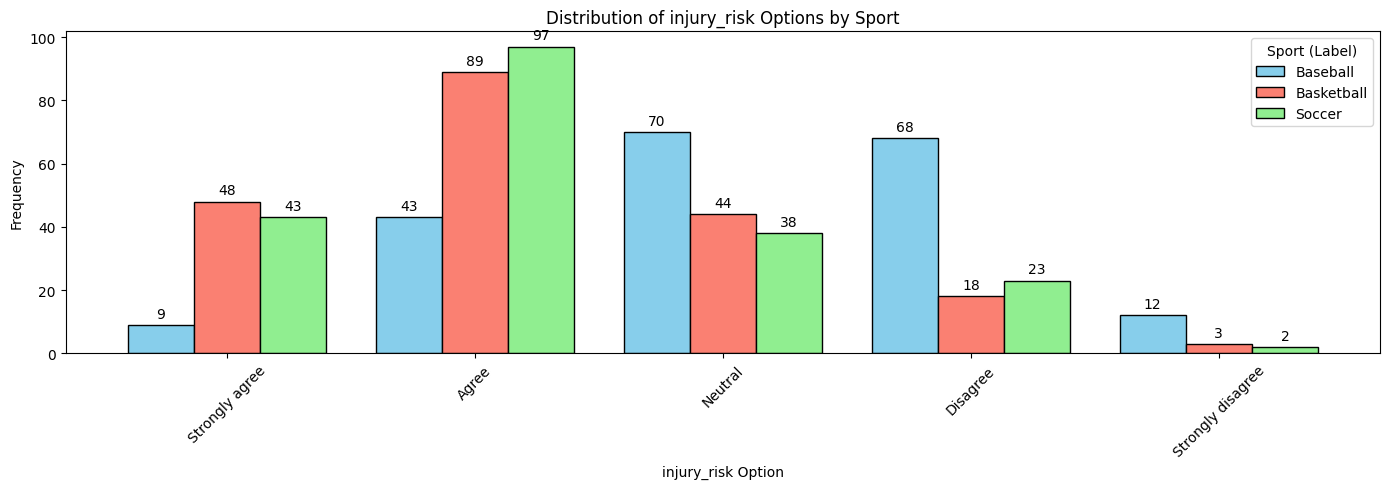

--- Summary Table: individual_brilliance (Counts) ---
label                  Baseball  Basketball  Soccer
individual_brilliance                              
Strongly agree               48          37      15
Agree                        88          82      45
Neutral                      37          42      60
Disagree                     23          34      68
Strongly disagree             6           6      15

--- Summary Table: individual_brilliance (Percentages) ---
label                  Baseball  Basketball  Soccer
individual_brilliance                              
Strongly agree            23.76       18.41    7.39
Agree                     43.56       40.80   22.17
Neutral                   18.32       20.90   29.56
Disagree                  11.39       16.92   33.50
Strongly disagree          2.97        2.99    7.39 



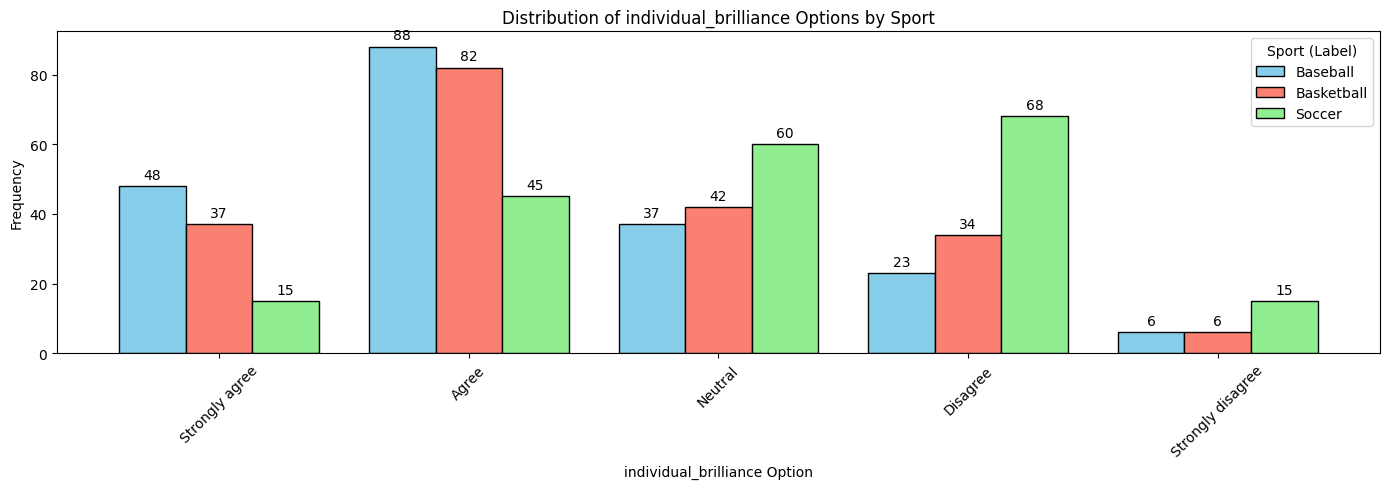

--- Summary Table: locations (Counts) ---
label                          Baseball  Basketball  Soccer
locations                                                  
Outdoor public space                177         179     192
School or university facility       152         189     180
Community recreation facility        96         180     157
Private sports facility             108         169     137
Indoor facility                      45         194     127
At home or nearby                    27         133      96
Others                                8          24      32

--- Summary Table: locations (Percentages) ---
label                          Baseball  Basketball  Soccer
locations                                                  
Outdoor public space              28.87       16.76   20.85
School or university facility     24.80       17.70   19.54
Community recreation facility     15.66       16.85   17.05
Private sports facility           17.62       15.82   14.88
Indoor fac

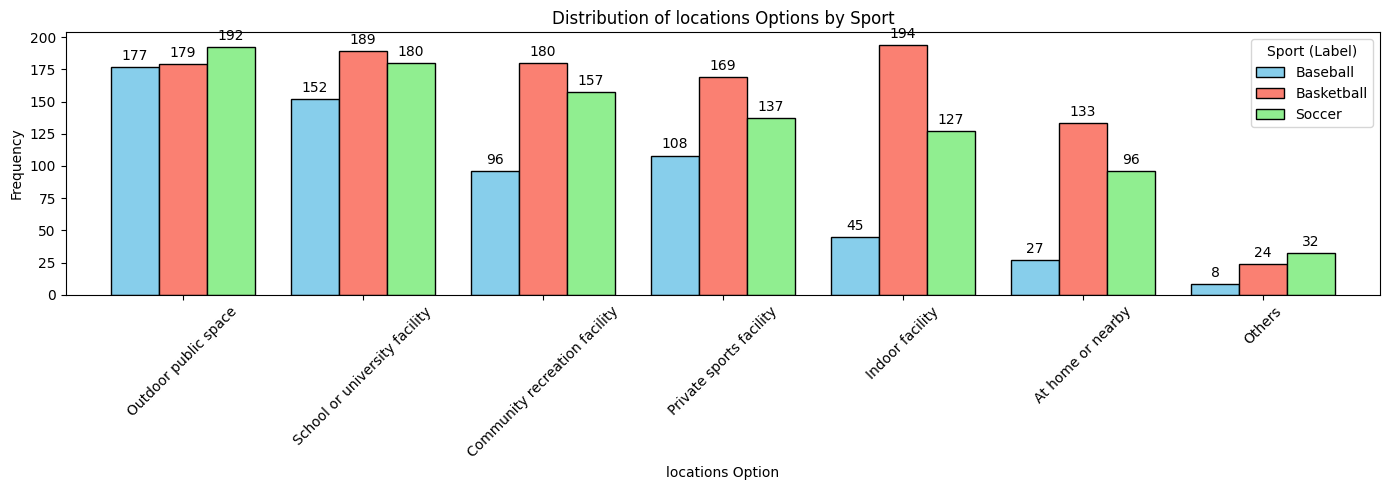

--- Summary Table: seasons (Counts) ---
label    Baseball  Basketball  Soccer
seasons                              
Summer        187         189     186
Spring        150         171     143
Fall          142         176     135
Winter         11         117      13

--- Summary Table: seasons (Percentages) ---
label    Baseball  Basketball  Soccer
seasons                              
Summer      38.16       28.94   38.99
Spring      30.61       26.19   29.98
Fall        28.98       26.95   28.30
Winter       2.24       17.92    2.73 



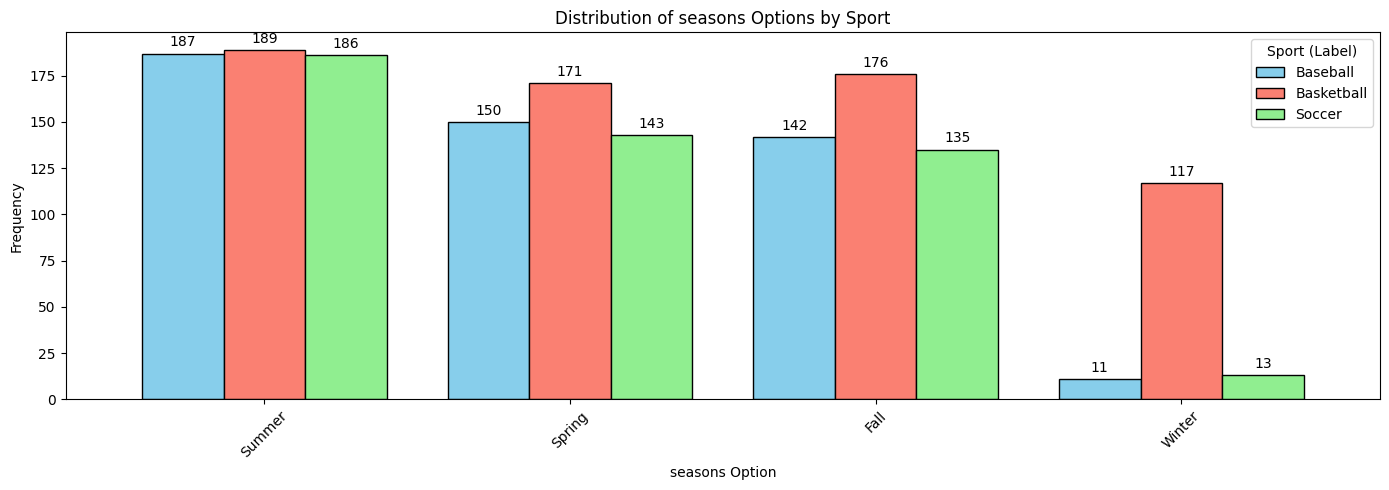

--- Summary Table: music_genre (Counts) ---
label                Baseball  Basketball  Soccer
music_genre                                      
Hip-hop or rap             53         170      83
Pop                        72         103      81
Rock                       49          56      45
Electronic or dance        29          38      73
No particular type         61          18      36
Latin                      12           1      82
Country                    66           6       7
Folk or traditional        20           4       8
Classical or jazz          13           3       3
Other                       4           8       5

--- Summary Table: music_genre (Percentages) ---
label                Baseball  Basketball  Soccer
music_genre                                      
Hip-hop or rap          13.98       41.77   19.62
Pop                     19.00       25.31   19.15
Rock                    12.93       13.76   10.64
Electronic or dance      7.65        9.34   17.26
No par

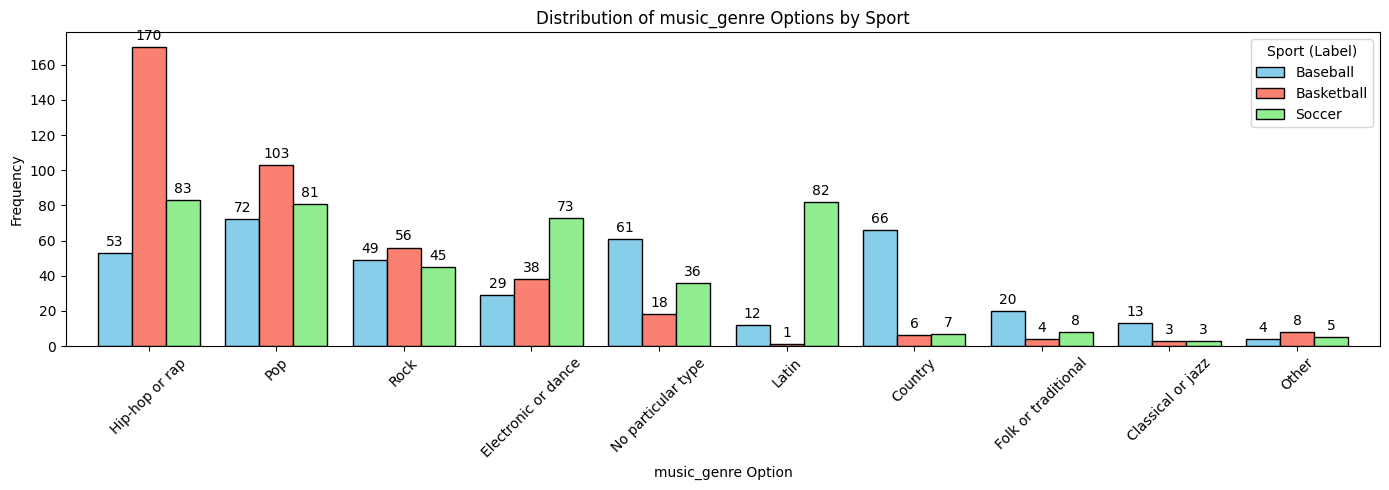


--- Summary Table: ticket_price (Counts) ---
label              Baseball  Basketball  Soccer
price_bin                                      
0.00 - 250.00           170         143     121
250.00 - 500.00          12          33      43
500.00 - 750.00           0           2       3
750.00 - 1000.00          2           6      15
1000.00 - 1250.00         0           2       1
1250.00 - 1500.00         0           0       1
1500.00 - 1750.00         0           0       0
1750.00 - 2000.00         0           2       2
2000.00 - 2250.00         0           0       0
2250.00 - 2500.00         0           0       0
2500.00 - 2750.00         0           0       0
2750.00 - 3000.00         0           0       0
3000.00 - 3250.00         0           0       0
3250.00 - 3500.00         0           0       0
3500.00 - 3750.00         0           0       0
3750.00 - 4000.00         0           0       0
4000.00 - 4250.00         0           0       0
4250.00 - 4500.00         0           0   

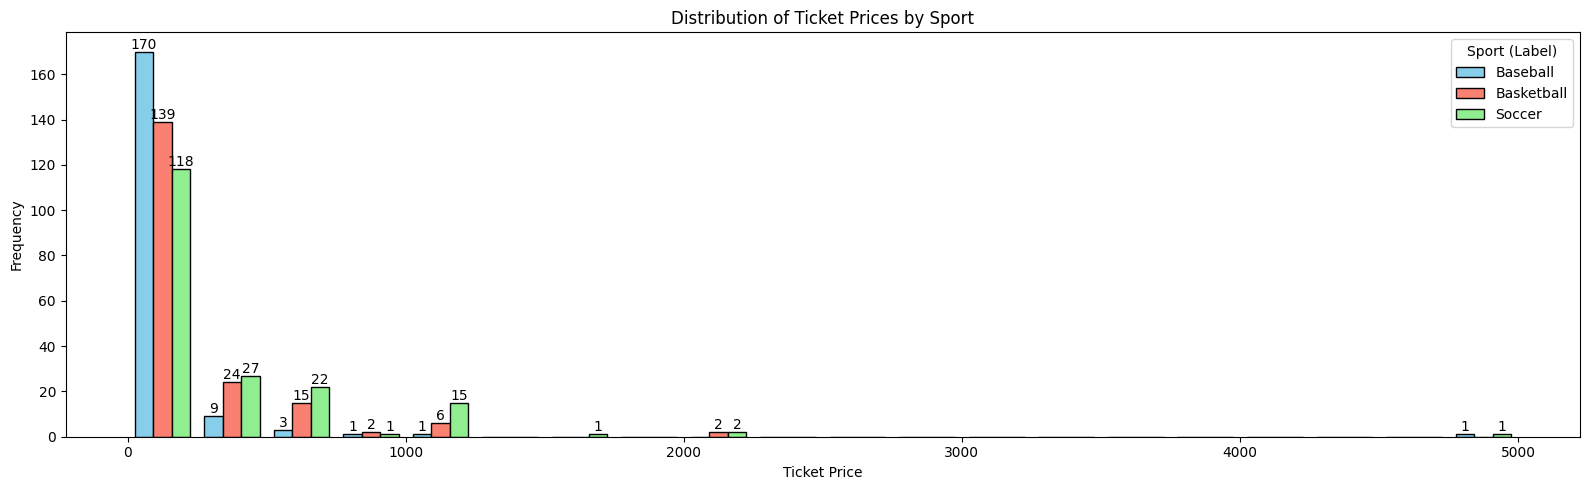

In [114]:
import pandas as pd
import matplotlib.pyplot as plt

train_df = pd.read_csv('raw/train.csv')

# Define standard orderings
likert_order = ['Strongly agree', 'Agree', 'Neutral', 'Disagree', 'Strongly disagree']
ease_order = list(range(11)) 

# Map sports to the exact colors used in the overall dataset plots
sport_colors = {
    'soccer': 'lightgreen', 
    'baseball': 'skyblue', 
    'basketball': 'salmon'
}

def apply_ordinal_sort(data, order_list):
    valid_order = [item for item in order_list if item in data.index]
    return data.loc[valid_order]


# 1. Grouped: Ease of Play
valid_ease_df = train_df[['ease_of_play', 'label']].dropna()
ease_crosstab = pd.crosstab(valid_ease_df['ease_of_play'], valid_ease_df['label'])
ease_crosstab = apply_ordinal_sort(ease_crosstab, ease_order)

ease_pct_crosstab = pd.crosstab(valid_ease_df['ease_of_play'], valid_ease_df['label'], normalize='columns')
ease_pct_crosstab = apply_ordinal_sort(ease_pct_crosstab, ease_order) * 100

print("--- Summary Table: ease_of_play (Counts) ---")
print(ease_crosstab)
print("\n--- Summary Table: ease_of_play (Percentages) ---")
print(ease_pct_crosstab.round(2), "\n")

plot_colors1 = [sport_colors.get(str(col).lower(), 'gray') for col in ease_crosstab.columns]

plt.figure(figsize=(14, 5))
ax1 = ease_crosstab.plot(kind='bar', figsize=(14, 5), color=plot_colors1, edgecolor='black', width=0.8)
for container in ax1.containers:
    ax1.bar_label(container, padding=3)
plt.title('Distribution of ease_of_play Options by Sport')
plt.xlabel('ease_of_play Option')
plt.ylabel('Frequency')
plt.legend(title='Sport (Label)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# 2. Grouped: Likert Scales
likert_cols = ['strategy_dependent', 'injury_risk', 'individual_brilliance']
for col in likert_cols:
    valid_likert_df = train_df[[col, 'label']].dropna()
    
    counts = pd.crosstab(valid_likert_df[col], valid_likert_df['label'])
    counts = apply_ordinal_sort(counts, likert_order)
    
    pct = pd.crosstab(valid_likert_df[col], valid_likert_df['label'], normalize='columns')
    pct = apply_ordinal_sort(pct, likert_order) * 100
    
    print(f"--- Summary Table: {col} (Counts) ---")
    print(counts)
    print(f"\n--- Summary Table: {col} (Percentages) ---")
    print(pct.round(2), "\n")

    plot_colors2 = [sport_colors.get(str(col_name).lower(), 'gray') for col_name in counts.columns]

    ax2 = counts.plot(kind='bar', figsize=(14, 5), color=plot_colors2, edgecolor='black', width=0.8)
    for container in ax2.containers:
        ax2.bar_label(container, padding=3)
    plt.title(f'Distribution of {col} Options by Sport')
    plt.xlabel(f'{col} Option')
    plt.ylabel('Frequency')
    plt.legend(title='Sport (Label)')
    plt.xticks(rotation=45) 
    plt.tight_layout()
    plt.show()


# 3. Grouped: Multi-Select Data
multiselect_cols = ['locations', 'seasons', 'music_genre']
for col in multiselect_cols:
    exploded_df = train_df[['label', col]].dropna()
    exploded_df[col] = exploded_df[col].str.split(',')
    exploded_df = exploded_df.explode(col)
    exploded_df[col] = exploded_df[col].str.strip()
    
    counts = pd.crosstab(exploded_df[col], exploded_df['label'])
    
    counts['Total'] = counts.sum(axis=1)
    counts = counts.sort_values('Total', ascending=False).drop(columns='Total')
    
    pct = pd.crosstab(exploded_df[col], exploded_df['label'], normalize='columns').loc[counts.index] * 100
    
    print(f"--- Summary Table: {col} (Counts) ---")
    print(counts)
    print(f"\n--- Summary Table: {col} (Percentages) ---")
    print(pct.round(2), "\n")
    
    plot_colors3 = [sport_colors.get(str(col_name).lower(), 'gray') for col_name in counts.columns]

    ax3 = counts.plot(kind='bar', figsize=(14, 5), color=plot_colors3, edgecolor='black', width=0.8)
    for container in ax3.containers:
        ax3.bar_label(container, padding=3)
    plt.title(f'Distribution of {col} Options by Sport')
    plt.xlabel(f'{col} Option')
    plt.ylabel('Frequency')
    plt.legend(title='Sport (Label)')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

import numpy as np

# 4. Grouped: Ticket Price
valid_price_df = train_df[['ticket_price', 'label']].copy()
# Extract numeric values and drop nulls
valid_price_df['ticket_price'] = valid_price_df['ticket_price'].astype(str).str.extract(r'(\d+\.?\d*)')[0].astype(float)
valid_price_df = valid_price_df.dropna()

_, bin_edges = np.histogram(valid_price_df['ticket_price'], bins=20)
bin_labels = [f"{bin_edges[i]:.2f} - {bin_edges[i+1]:.2f}" for i in range(len(bin_edges)-1)]

# Categorize the original data using these exact edges
valid_price_df['price_bin'] = pd.cut(valid_price_df['ticket_price'], bins=bin_edges, include_lowest=True, labels=bin_labels)

counts = pd.crosstab(valid_price_df['price_bin'], valid_price_df['label'], dropna=False)
pct = pd.crosstab(valid_price_df['price_bin'], valid_price_df['label'], normalize='columns', dropna=False) * 100

print(f"\n--- Summary Table: ticket_price (Counts) ---")
print(counts)
print(f"\n--- Summary Table: ticket_price (Percentages) ---")
print(pct.round(2), "\n")

# Map colors to the specific order of sports in the dataframe columns
plot_colors4 = [sport_colors.get(str(col).lower(), 'gray') for col in counts.columns]

plt.figure(figsize=(16, 5))

sports = counts.columns 
data_to_plot = [valid_price_df[valid_price_df['label'] == sport]['ticket_price'].dropna() for sport in sports]

n, bins, patches = plt.hist(data_to_plot, bins=20, color=plot_colors4, edgecolor='black', label=sports)

for sport_patches in patches:
    for patch in sport_patches:
        height = patch.get_height()
        if height > 0: 
            plt.text(patch.get_x() + patch.get_width() / 2, height, f'{int(height)}', 
                     ha='center', va='bottom')

plt.title('Distribution of Ticket Prices by Sport')
plt.xlabel('Ticket Price')
plt.ylabel('Frequency')
plt.legend(title='Sport (Label)')
plt.tight_layout()
plt.show()

#### 3. Feature Engineering & Missing Values Handling

In [115]:
import pandas as pd

train_df = pd.read_csv('raw/train.csv')

# 1. Remove the 'id' column
if 'id' in train_df.columns:
    train_df = train_df.drop(columns=['id'])


feature_cols = [col for col in train_df.columns if col != 'label']
total_rows = len(train_df)

# 2. Count missing values and percentages in each column
missing_counts = train_df.isna().sum()
missing_percentages = (missing_counts / total_rows) * 100

# Combine into a DataFrame for clean formatting
missing_stats = pd.DataFrame({
    'Missing Count': missing_counts,
    'Percentage (%)': missing_percentages.round(2)
})

print("--- Missing Values per Column ---")
# Filter to only show columns that actually have missing values
print(missing_stats)

# 3. Count rows where ALL feature inputs are empty, with percentage
all_empty_rows_count = train_df[feature_cols].isna().all(axis=1).sum()
all_empty_rows_pct = (all_empty_rows_count / total_rows) * 100

print(f"\nRows with ALL feature inputs empty: {all_empty_rows_count} ({all_empty_rows_pct:.2f}%)")

# Calculate missing counts and percentages grouped by the target label (sport)
missing_counts_by_sport = train_df.groupby('label').agg(lambda x: x.isna().sum()).T
missing_pct_by_sport = train_df.groupby('label').agg(lambda x: (x.isna().mean() * 100).round(2)).T

print("\n--- Missing Values per Column by Sport ---")
print("\nCounts:")
print(missing_counts_by_sport)

print("\nPercentages (%):")
print(missing_pct_by_sport)

--- Missing Values per Column ---
                       Missing Count  Percentage (%)
ease_of_play                       5            0.82
strategy_dependent                 6            0.98
injury_risk                        5            0.82
individual_brilliance              6            0.98
locations                          5            0.82
seasons                            5            0.82
music_genre                        5            0.82
food_drink                        17            2.78
color                              9            1.47
song                              53            8.66
emotions                           6            0.98
ticket_price                       7            1.14
label                              0            0.00

Rows with ALL feature inputs empty: 5 (0.82%)

--- Missing Values per Column by Sport ---

Counts:
label                  Baseball  Basketball  Soccer
ease_of_play                  2           2       1
strategy_dependent  

In [116]:
import json
import math
import numpy as np
import pandas as pd
import os

train_df = pd.read_csv('raw/train.csv')

if 'id' in train_df.columns:
    train_df = train_df.drop(columns=['id'])

# Ensure feature_cols is defined for the dropna step
feature_cols = [col for col in train_df.columns if col != 'label']

# --- 1. Remove rows where all feature inputs are empty ---
train_df = train_df.dropna(how='all', subset=feature_cols).copy()

# --- 2. Extract ticket price to numerical ---
train_df['ticket_price'] = train_df['ticket_price'].astype(str).str.extract(r'(\d+\.?\d*)')[0]
train_df['ticket_price'] = pd.to_numeric(train_df['ticket_price'], errors='coerce')

# --- 3. Turn categorical into ordinal numbers ---
likert_mapping = {
    'Strongly disagree': 1,
    'Disagree': 2,
    'Neutral': 3,
    'Agree': 4,
    'Strongly agree': 5
}
likert_cols = ['strategy_dependent', 'injury_risk', 'individual_brilliance']
for col in likert_cols:
    train_df[col] = train_df[col].map(likert_mapping)

# --- 4. Calculate Medians, Save to File, and Impute ---
cols_to_impute = ['ease_of_play', 'ticket_price'] + likert_cols
medians = train_df[cols_to_impute].median().to_dict()

# Save medians to a JSON file for future reference/inference
os.makedirs('processed', exist_ok=True)
with open('processed/imputed_medians.json', 'w') as f:
    json.dump(medians, f, indent=4)

# Fill missing values with the calculated medians
for col in cols_to_impute:
    train_df[col] = train_df[col].fillna(medians[col])

# --- 5. Multi-select with NULL indicator ---
multiselect_cols = ['locations', 'seasons', 'music_genre']
encoded_multiselect = []

for col in multiselect_cols:
    # Filling with 'NULL_INDICATOR' ensures it gets its own one-hot column during get_dummies
    temp_series = train_df[col].fillna('NULL_INDICATOR')
    dummies = temp_series.str.get_dummies(sep=',')
    
    # Rename columns to track the source feature
    dummies.columns = [f"{col}_{c.strip()}" for c in dummies.columns]
    encoded_multiselect.append(dummies)

# Drop original multi-select columns and join the one-hot encoded ones
train_df = train_df.drop(columns=multiselect_cols)
train_df = pd.concat([train_df] + encoded_multiselect, axis=1)

# --- 6. Custom TF-IDF Implementation (No Libraries) ---
def compute_custom_tfidf(text_series, prefix, max_vocab=50):
    """Calculates TF-IDF from scratch and returns a DataFrame of vectors AND the learned vocabulary/weights."""
    # Fill missing with "null", lowercase, and split into alphanumeric tokens
    docs = text_series.fillna('null').astype(str).str.lower().str.split(r'\W+')
    docs = docs.apply(lambda x: [w for w in x if w])
    
    total_docs = len(docs)
    df_counts = {}
    
    # Calculate Document Frequency (DF)
    for doc in docs:
        for word in set(doc):
            df_counts[word] = df_counts.get(word, 0) + 1
            
    # Calculate smoothed Inverse Document Frequency (IDF)
    idf = {word: math.log(total_docs / (count + 1)) + 1 for word, count in df_counts.items()}
    
    # Limit vocabulary to top K most frequent words
    top_words = sorted(idf.keys(), key=lambda w: df_counts[w], reverse=True)[:max_vocab]
    
    # Isolate the exact IDF scores for just the top words so we can export them
    learned_idf = {word: idf[word] for word in top_words}
    
    # Calculate Term Frequency (TF) and TF-IDF
    tfidf_matrix = []
    for doc in docs:
        doc_len = len(doc)
        doc_counts = {}
        for w in doc:
            doc_counts[w] = doc_counts.get(w, 0) + 1
            
        row = {}
        for word in top_words:
            tf = doc_counts.get(word, 0) / doc_len if doc_len > 0 else 0
            row[f'{prefix}_{word}'] = tf * learned_idf[word]
        tfidf_matrix.append(row)
        
    return pd.DataFrame(tfidf_matrix, index=text_series.index), learned_idf

free_text_cols = ['food_drink', 'color', 'song', 'emotions']
encoded_text_dfs = []
tfidf_metadata = {}

for col in free_text_cols:
    # Unpack the tuple returned by the updated function
    tfidf_df, learned_idf = compute_custom_tfidf(train_df[col], prefix=col, max_vocab=25)
    encoded_text_dfs.append(tfidf_df)
    tfidf_metadata[col] = learned_idf

# Drop original free text columns and join the custom TF-IDF columns
train_df = train_df.drop(columns=free_text_cols)
train_df = pd.concat([train_df] + encoded_text_dfs, axis=1)

# Save the learned vocabulary and IDF scores for the test set
with open('processed/tfidf_metadata.json', 'w') as f:
    json.dump(tfidf_metadata, f, indent=4)

# --- 7. Save the processed training dataset ---
train_df.to_csv('processed/train_engineered.csv', index=False)
print("Data engineering complete. Files saved to 'processed/' directory.")

Data engineering complete. Files saved to 'processed/' directory.


#### 4. Feature Selection

Calculating Mutual Information to filter noise...


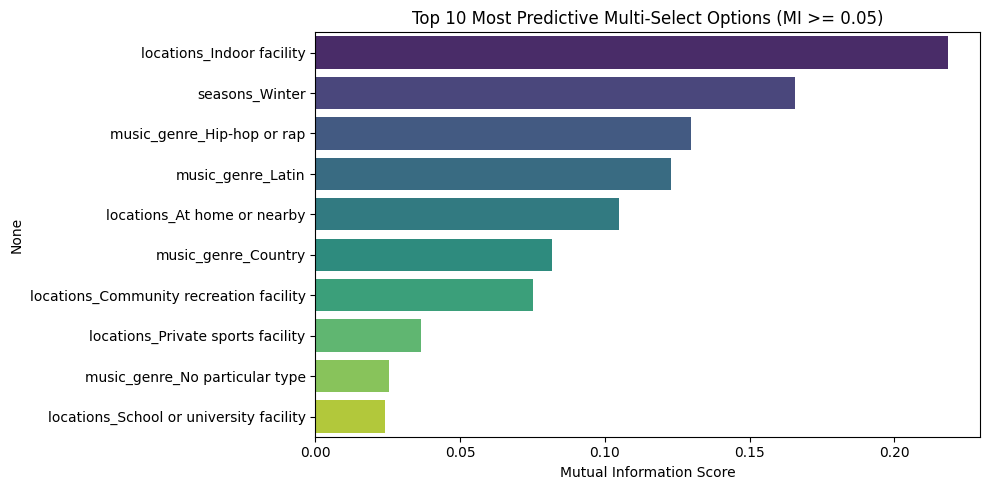

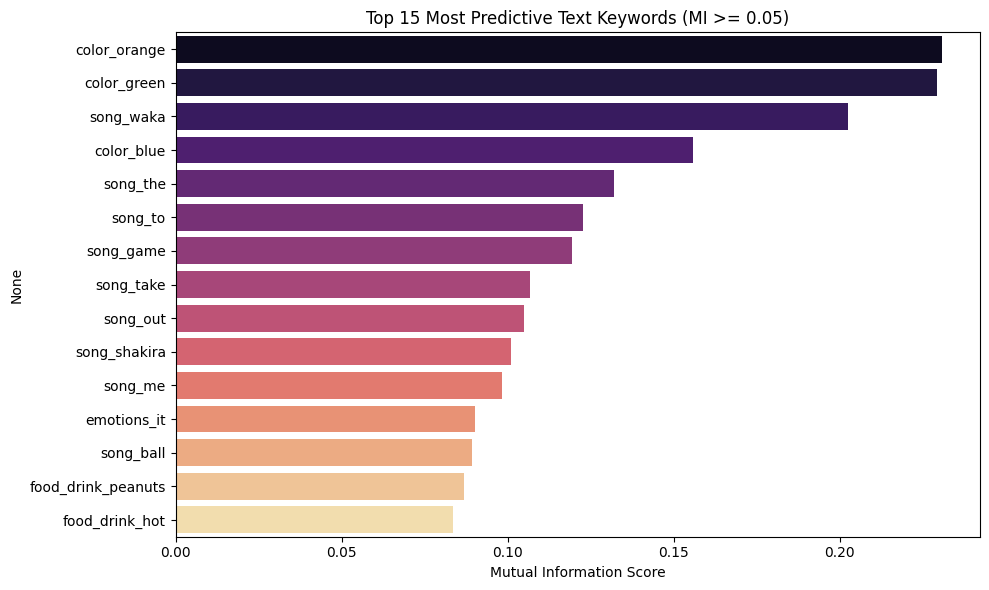

Identified 93 low-importance features to drop (Score < 0.05).

Calculating global correlation matrix on surviving features...


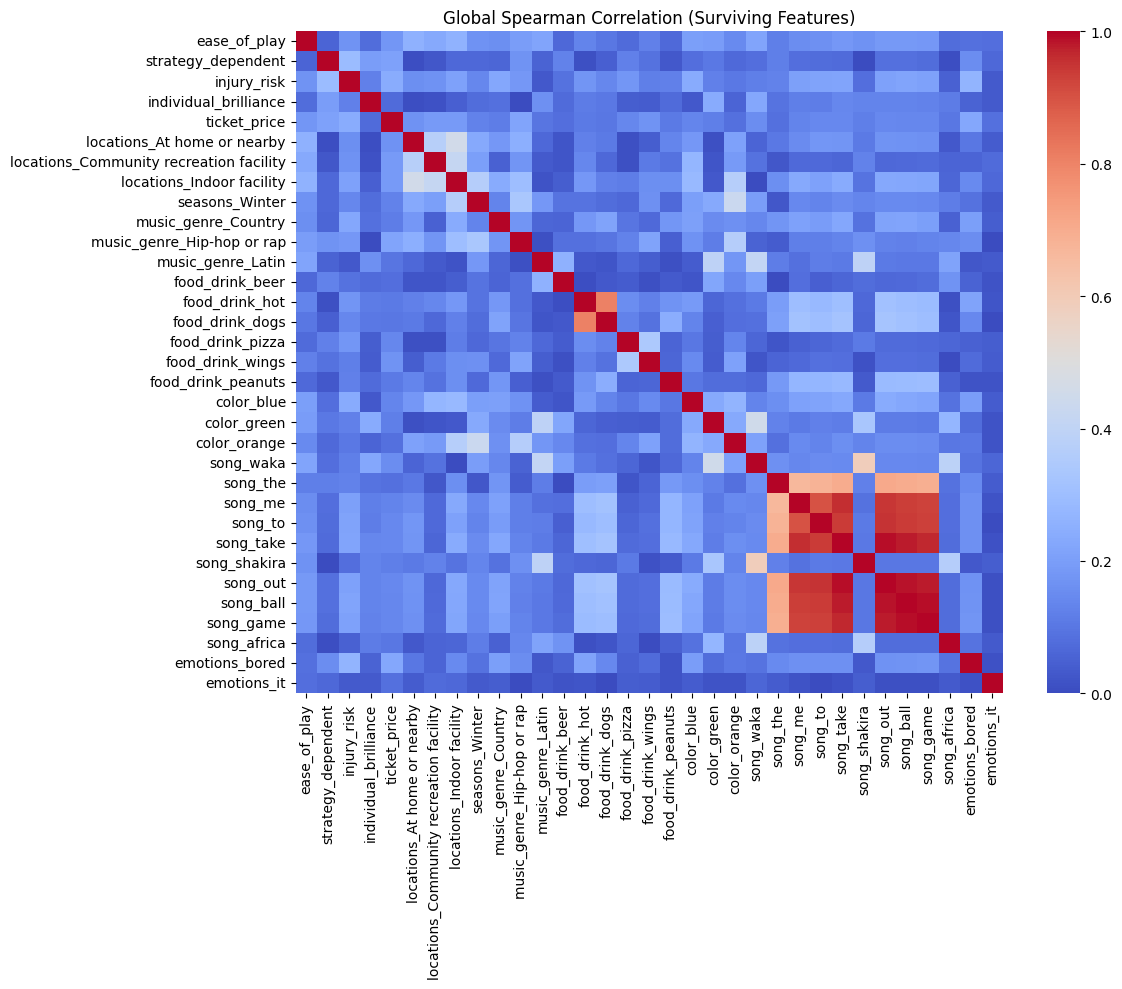

Identified 6 highly correlated redundant features to drop.

Kept 27 features for final model training.
Final training dataset shape: (607, 28). Saved to 'processed/train_selected.csv'.


In [117]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import mutual_info_classif

CORR_THRESHOLD = 0.8
MI_THRESHOLD = 0.05

train_df = pd.read_csv('processed/train_engineered.csv')

y_target = train_df['label'].astype('category').cat.codes

# Define feature groups
numeric_cols = ['ease_of_play', 'ticket_price', 'strategy_dependent', 'injury_risk', 'individual_brilliance']
multiselect_cols = [col for col in train_df.columns if col.startswith(('locations_', 'seasons_', 'music_genre_'))]
text_cols = [col for col in train_df.columns if col.startswith(('food_drink_', 'color_', 'song_', 'emotions_'))]

features_to_drop = []

# --- 1. Filter by Mutual Information (Categorical/Text Only) ---
print("Calculating Mutual Information to filter noise...")
mi_scores_multi = mutual_info_classif(train_df[multiselect_cols], y_target, discrete_features=True, random_state=42)
mi_scores_text = mutual_info_classif(train_df[text_cols], y_target, discrete_features=False, random_state=42)

multi_mi_dict = dict(zip(multiselect_cols, mi_scores_multi))
text_mi_dict = dict(zip(text_cols, mi_scores_text))

# GRAPH 1: Top 10 Multi-Select Options
ms_results = pd.Series(multi_mi_dict).sort_values(ascending=False).head(10)
plt.figure(figsize=(10, 5))
sns.barplot(x=ms_results.values, y=ms_results.index, hue=ms_results.index, legend=False, palette='viridis')
plt.title(f"Top 10 Most Predictive Multi-Select Options (MI >= {MI_THRESHOLD})")
plt.xlabel("Mutual Information Score")
plt.tight_layout()
plt.show()

# GRAPH 2: Top 15 Free Text Keywords
text_results = pd.Series(text_mi_dict).sort_values(ascending=False).head(15)
plt.figure(figsize=(10, 6))
sns.barplot(x=text_results.values, y=text_results.index, hue=text_results.index, legend=False, palette='magma')
plt.title(f"Top 15 Most Predictive Text Keywords (MI >= {MI_THRESHOLD})")
plt.xlabel("Mutual Information Score")
plt.tight_layout()
plt.show()

# Identify features that fall below the threshold
low_mi_drops = [feat for feat, score in multi_mi_dict.items() if score < MI_THRESHOLD] + \
               [feat for feat, score in text_mi_dict.items() if score < MI_THRESHOLD]
features_to_drop.extend(low_mi_drops)
print(f"Identified {len(low_mi_drops)} low-importance features to drop (Score < {MI_THRESHOLD}).")

# --- 2. Global Correlation on ALL Surviving Features ---
surviving_features = [col for col in train_df.columns if col not in features_to_drop and col != 'label']
corr_check_df = train_df[surviving_features]

print("\nCalculating global correlation matrix on surviving features...")
corr_matrix = corr_check_df.corr(method='spearman').abs()

# GRAPH 3: Global Correlation Heatmap of Surviving Features
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', vmin=0, vmax=1)
plt.title('Global Spearman Correlation (Surviving Features)')
plt.tight_layout()
plt.show()

# Select the upper triangle to avoid dropping both sides of a correlated pair
upper_triangle = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

# Find surviving features that are highly correlated with another surviving feature
correlated_drops = [column for column in upper_triangle.columns if any(upper_triangle[column] > CORR_THRESHOLD)]
features_to_drop.extend(correlated_drops)
print(f"Identified {len(correlated_drops)} highly correlated redundant features to drop.")

# --- 3. Store rules and execute drops ---
train_selected_df = train_df.drop(columns=features_to_drop)

# Extract the final list of features that survived (excluding the target label)
features_kept = [col for col in train_selected_df.columns if col != 'label']

selection_results = {
    "correlation_threshold_used": CORR_THRESHOLD,
    "mi_threshold_used": MI_THRESHOLD,
    "low_mi_features_dropped": low_mi_drops,
    "correlated_features_dropped": correlated_drops,
    "features_kept": features_kept,
    "multiselect_mi_scores": multi_mi_dict,
    "text_mi_scores": text_mi_dict
}

with open('processed/feature_selection_scores.json', 'w') as f:
    json.dump(selection_results, f, indent=4)

train_selected_df.to_csv('processed/train_selected.csv', index=False)

print(f"\nKept {len(features_kept)} features for final model training.")
print(f"Final training dataset shape: {train_selected_df.shape}. Saved to 'processed/train_selected.csv'.")

#### 5. Feature Scaling

In [118]:
import pandas as pd
import json

# 1. Load the finalized, feature-selected dataset
train_selected_df = pd.read_csv('processed/train_selected.csv')

# 2. Separate features from the target label
X_train = train_selected_df.drop(columns=['label'])
y_train = train_selected_df['label']

# 3. Calculate parameters and scale (Standardization: Z-score)
scaling_params = {}

for col in X_train.columns:
    mean_val = X_train[col].mean()
    std_val = X_train[col].std(ddof=0)  # ddof=0 calculates population standard deviation
    
    # Safety net: If a feature is perfectly constant, prevent division by zero
    if std_val == 0:
        std_val = 1.0
        
    # Store the parameters for test-set inference
    scaling_params[col] = {'mean': mean_val, 'std': std_val}
    
    # Apply the scaling transformation: (Value - Mean) / Standard Deviation
    X_train[col] = (X_train[col] - mean_val) / std_val

# 4. Save the scaling rules for the test set
with open('processed/scaling_params.json', 'w') as f:
    json.dump(scaling_params, f, indent=4)

# 5. Recombine the scaled features with the target label and save
train_scaled_df = pd.concat([X_train, y_train], axis=1)
train_scaled_df.to_csv('processed/train_scaled.csv', index=False)

print("Feature scaling complete.")
print("Scaling parameters saved to 'processed/scaling_params.json'.")
print(f"Final scaled dataset shape: {train_scaled_df.shape}. Saved to 'processed/train_scaled.csv'.")

Feature scaling complete.
Scaling parameters saved to 'processed/scaling_params.json'.
Final scaled dataset shape: (607, 28). Saved to 'processed/train_scaled.csv'.


#### 6. Pre-testing Models

In [119]:
import json
import pandas as pd
import numpy as np

def compute_tfidf_inference(text_series, prefix, saved_idf):
    """Applies saved IDF weights to new text data."""
    docs = text_series.fillna('null').astype(str).str.lower().str.split(r'\W+')
    docs = docs.apply(lambda x: [w for w in x if w])
    
    tfidf_matrix = []
    for doc in docs:
        doc_len = len(doc)
        doc_counts = {}
        for w in doc:
            doc_counts[w] = doc_counts.get(w, 0) + 1
            
        row = {}
        for word, idf_val in saved_idf.items():
            tf = doc_counts.get(word, 0) / doc_len if doc_len > 0 else 0
            row[f'{prefix}_{word}'] = tf * idf_val
        tfidf_matrix.append(row)
    return pd.DataFrame(tfidf_matrix, index=text_series.index)

def process_unseen_data(input_filepath, output_filepath):
    # 1. Load data and JSON metadata
    df = pd.read_csv(input_filepath)
    with open('processed/imputed_medians.json', 'r') as f:
        medians = json.load(f)
    with open('processed/tfidf_metadata.json', 'r') as f:
        tfidf_metadata = json.load(f)
    with open('processed/scaling_params.json', 'r') as f:
        scaling_params = json.load(f)
        
    expected_features = list(scaling_params.keys())

    # 2. Rename columns using exact mapping
    column_mapping = {
        'How easy do you think it would be for someone with no prior experience to start playing this sport recreationally? Rate it on a scale from 0 to 10, where 0 means extremely difficult and 10 means extremely easy.': 'ease_of_play',
        'Success in this sport depends heavily on strategy and planning.': 'strategy_dependent',
        'Players must be comfortable with a high risk of injury.': 'injury_risk',
        'Individual brilliance can outweigh teamwork in this sport.': 'individual_brilliance',
        'Where might you play this sport?': 'locations',
        'During which seasons would you be most likely to play this sport recreationally in Toronto?': 'seasons',
        'What types of music do you most associate with this sport?': 'music_genre',
        'What foods and drinks do you associate with watching this sport in the place or culture you know best?': 'food_drink',
        'What colour do you associate with this sport?': 'color',
        'Which song do you associate with this sport?': 'song',
        'How do you feel when you watch this sport?': 'emotions',
        'How much would you be willing to pay for a decent seat at a professional competition of this sport?': 'ticket_price'
    }
    df = df.rename(columns=column_mapping)
    
    if 'id' in df.columns:
        df = df.drop(columns=['id'])

    # 3. Numeric & Ordinal Engineering
    df['ticket_price'] = df['ticket_price'].astype(str).str.extract(r'(\d+\.?\d*)')[0]
    df['ticket_price'] = pd.to_numeric(df['ticket_price'], errors='coerce')

    likert_mapping = {'Strongly disagree': 1, 'Disagree': 2, 'Neutral': 3, 'Agree': 4, 'Strongly agree': 5}
    for col in ['strategy_dependent', 'injury_risk', 'individual_brilliance']:
        df[col] = df[col].map(likert_mapping)

    # 4. Impute Saved Medians
    for col, median_val in medians.items():
        if col in df.columns:
            df[col] = df[col].fillna(median_val)

    # 5. Multi-select Encoding
    multiselect_cols = ['locations', 'seasons', 'music_genre']
    encoded_multiselect = []
    for col in multiselect_cols:
        temp_series = df[col].fillna('NULL_INDICATOR')
        dummies = temp_series.str.get_dummies(sep=',')
        dummies.columns = [f"{col}_{c.strip()}" for c in dummies.columns]
        encoded_multiselect.append(dummies)
        
    df = df.drop(columns=multiselect_cols)
    df = pd.concat([df] + encoded_multiselect, axis=1)

    # 6. TF-IDF Inference
    free_text_cols = ['food_drink', 'color', 'song', 'emotions']
    encoded_text_dfs = []
    for col in free_text_cols:
        saved_idf = tfidf_metadata.get(col, {})
        tfidf_df = compute_tfidf_inference(df[col], prefix=col, saved_idf=saved_idf)
        encoded_text_dfs.append(tfidf_df)
        
    df = df.drop(columns=free_text_cols)
    df = pd.concat([df] + encoded_text_dfs, axis=1)

    # 7. Target Encoding
    label_mapping = {
        'Baseball': 0,
        'Basketball': 1,
        'Soccer': 2
    }
    df['label'] = df['label'].map(label_mapping)

    # 8. Align Features to Training State (Drop irrelevant/redundant, add missing)
    for expected_col in expected_features:
        if expected_col not in df.columns:
            df[expected_col] = 0.0  # Fill 0 if test set lacked a specific multi-select category
            
    # Keep only the target label and the features that survived training selection
    final_cols = expected_features + ['label']
    df = df[final_cols]

    # 9. Apply Saved Scaling
    for col in expected_features:
        mean_val = scaling_params[col]['mean']
        std_val = scaling_params[col]['std']
        df[col] = (df[col] - mean_val) / std_val

    df.to_csv(output_filepath, index=False)
    print(f"Processed and saved to {output_filepath}")

# Process the raw validation and test datasets
process_unseen_data('raw/val.csv', 'processed/val_scaled.csv')
process_unseen_data('raw/test.csv', 'processed/test_scaled.csv')

Processed and saved to processed/val_scaled.csv
Processed and saved to processed/test_scaled.csv


In [120]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

def standardize_labels(df):
    """Safely converts string labels to standard integers without dropping rows."""
    if df['label'].dtype == 'object' or df['label'].dtype == 'string':
        mapping = {'baseball': 0, 'basketball': 1, 'soccer': 2}
        df['label'] = df['label'].astype(str).str.lower().str.strip().map(mapping)
    
    df.dropna(subset=['label'], inplace=True)
    df['label'] = df['label'].astype(int)
    return df

def plot_cm(y_true, y_pred, title):
    """Generates a labeled heatmap for the confusion matrix."""
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(7, 5))
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues',
        xticklabels=['Baseball', 'Basketball', 'Soccer'], 
        yticklabels=['Baseball', 'Basketball', 'Soccer']
    )
    plt.title(title)
    plt.xlabel('Predicted Sport')
    plt.ylabel('True Sport')
    plt.tight_layout()
    plt.show()

# Load and standardize datasets
train_df = standardize_labels(pd.read_csv('processed/train_scaled.csv'))
val_df = standardize_labels(pd.read_csv('processed/val_scaled.csv'))
test_df = standardize_labels(pd.read_csv('processed/test_scaled.csv'))

# Split features and target
X_train, y_train = train_df.drop(columns=['label']), train_df['label']
X_val, y_val = val_df.drop(columns=['label']), val_df['label']
X_test, y_test = test_df.drop(columns=['label']), test_df['label']

print(f"Data ready. Training: {len(X_train)} | Validation: {len(X_val)} | Test: {len(X_test)}")

Data ready. Training: 607 | Validation: 129 | Test: 129


Logistic Regression

Tuning Softmax Regression...
Best Hyperparameter (C): 1 | Validation Accuracy: 0.8450

--- Softmax Regression Test Results ---

Classification Report:
               precision    recall  f1-score   support

           0       0.84      0.88      0.86        43
           1       0.85      0.95      0.90        43
           2       0.97      0.81      0.89        43

    accuracy                           0.88       129
   macro avg       0.89      0.88      0.88       129
weighted avg       0.89      0.88      0.88       129



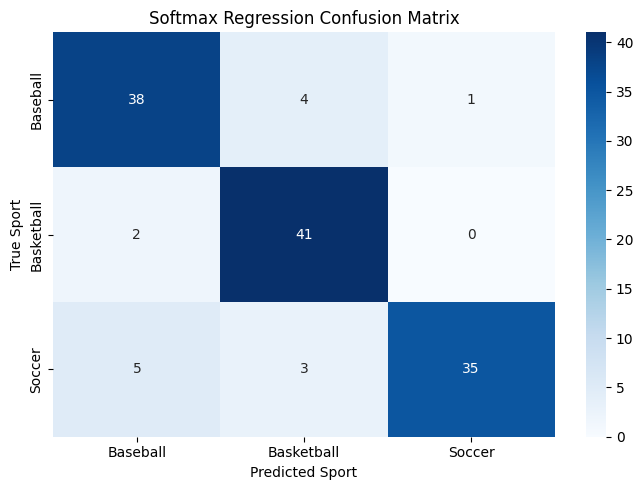

In [121]:
from sklearn.linear_model import LogisticRegression

# Tune Hyperparameters on Validation Set
c_values = [0.01, 0.1, 1, 10, 100]
best_score = -1 
best_c = None
best_model_softmax = None

print("Tuning Softmax Regression...")
for c in c_values:
    model = LogisticRegression(solver='lbfgs', C=c, max_iter=1000, random_state=42)
    model.fit(X_train, y_train)
    score = model.score(X_val, y_val)
    if score > best_score:
        best_score = score
        best_c = c
        best_model_softmax = model

print(f"Best Hyperparameter (C): {best_c} | Validation Accuracy: {best_score:.4f}")

# Test and Visualize
y_pred = best_model_softmax.predict(X_test)
print("\n--- Softmax Regression Test Results ---")
print("\nClassification Report:\n", classification_report(y_test, y_pred))
plot_cm(y_test, y_pred, 'Softmax Regression Confusion Matrix')

MLP

Tuning MLP...
Best Hyperparameters: {'hidden_layer_sizes': (32,), 'alpha': 0.0001} | Validation Accuracy: 0.8682

--- MLP Test Results ---

Classification Report:
               precision    recall  f1-score   support

           0       0.87      0.91      0.89        43
           1       0.87      0.93      0.90        43
           2       0.97      0.86      0.91        43

    accuracy                           0.90       129
   macro avg       0.90      0.90      0.90       129
weighted avg       0.90      0.90      0.90       129



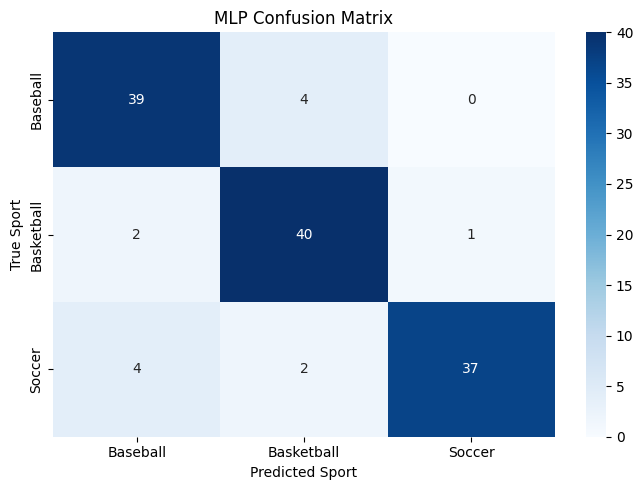

In [122]:
from sklearn.neural_network import MLPClassifier

hidden_layers = [(32,), (64,), (32, 16), (50,), (100,), (50, 25)]
alphas = [0.0001, 0.001, 0.01]
best_score = -1
best_params = {}
best_model_mlp = None

print("Tuning MLP...")
for layers in hidden_layers:
    for alpha in alphas:
        model = MLPClassifier(hidden_layer_sizes=layers, alpha=alpha, max_iter=1000, random_state=42)
        model.fit(X_train, y_train)
        score = model.score(X_val, y_val)
        if score > best_score:
            best_score = score
            best_params = {'hidden_layer_sizes': layers, 'alpha': alpha}
            best_model_mlp = model

print(f"Best Hyperparameters: {best_params} | Validation Accuracy: {best_score:.4f}")

y_pred = best_model_mlp.predict(X_test)
print("\n--- MLP Test Results ---")
print("\nClassification Report:\n", classification_report(y_test, y_pred))
plot_cm(y_test, y_pred, 'MLP Confusion Matrix')

Random Forest

Tuning Random Forest...
Best Hyperparameters: {'n_estimators': 50, 'max_depth': 20} | Validation Accuracy: 0.8372

--- Random Forest Test Results ---

Classification Report:
               precision    recall  f1-score   support

           0       0.88      0.88      0.88        43
           1       0.84      0.98      0.90        43
           2       0.97      0.81      0.89        43

    accuracy                           0.89       129
   macro avg       0.90      0.89      0.89       129
weighted avg       0.90      0.89      0.89       129



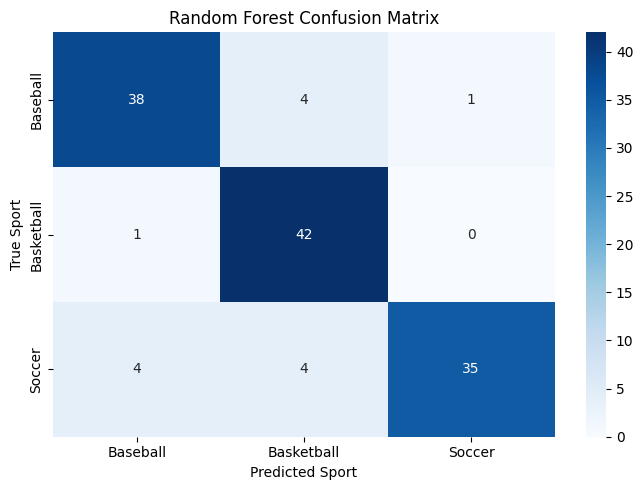

In [123]:
from sklearn.ensemble import RandomForestClassifier

n_estimators_list = [50, 100, 200]
max_depths = [None, 5, 10, 20]
best_score = -1
best_params = {}
best_model_rf = None

print("Tuning Random Forest...")
for n in n_estimators_list:
    for depth in max_depths:
        model = RandomForestClassifier(n_estimators=n, max_depth=depth, random_state=42)
        model.fit(X_train, y_train)
        score = model.score(X_val, y_val)
        if score > best_score:
            best_score = score
            best_params = {'n_estimators': n, 'max_depth': depth}
            best_model_rf = model

print(f"Best Hyperparameters: {best_params} | Validation Accuracy: {best_score:.4f}")

y_pred = best_model_rf.predict(X_test)
print("\n--- Random Forest Test Results ---")
print("\nClassification Report:\n", classification_report(y_test, y_pred))
plot_cm(y_test, y_pred, 'Random Forest Confusion Matrix')

Naive Bayes

Tuning Naive Bayes...
Best Hyperparameter (var_smoothing): 1e-08 | Validation Accuracy: 0.7674

--- Naive Bayes Test Results ---

Classification Report:
               precision    recall  f1-score   support

           0       0.69      0.88      0.78        43
           1       0.82      0.93      0.87        43
           2       1.00      0.58      0.74        43

    accuracy                           0.80       129
   macro avg       0.84      0.80      0.79       129
weighted avg       0.84      0.80      0.79       129



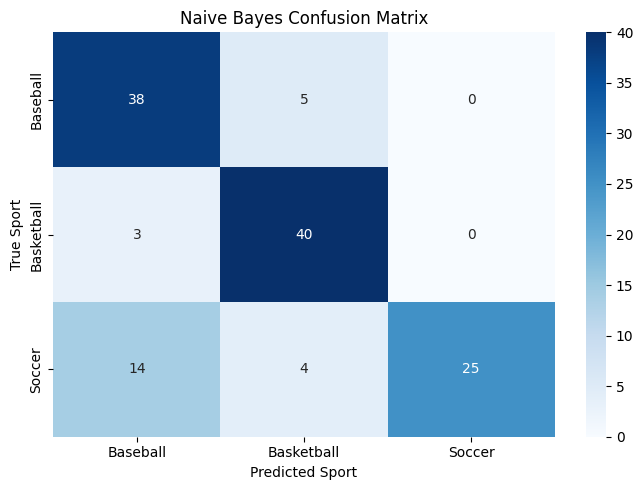

In [124]:
from sklearn.naive_bayes import GaussianNB

var_smoothings = [1e-9, 1e-8, 1e-7, 1e-6]
best_score = -1
best_smoothing = None
best_model_nb = None

print("Tuning Naive Bayes...")
for vs in var_smoothings:
    model = GaussianNB(var_smoothing=vs)
    model.fit(X_train, y_train)
    score = model.score(X_val, y_val)
    if score > best_score:
        best_score = score
        best_smoothing = vs
        best_model_nb = model

print(f"Best Hyperparameter (var_smoothing): {best_smoothing} | Validation Accuracy: {best_score:.4f}")

y_pred = best_model_nb.predict(X_test)
print("\n--- Naive Bayes Test Results ---")
print("\nClassification Report:\n", classification_report(y_test, y_pred))
plot_cm(y_test, y_pred, 'Naive Bayes Confusion Matrix')